# Spectral clustering

Spectral clustering is an advanced unsupervised machine learning algorithm that groups data points using the eigenvalues and eigenvectors of a similarity matrix

# For more information click the link below the section

https://docs.google.com/document/d/1t0qsoSBFtDfkCEt96l-go4zQ2MFJUnWgEGJCBU7reic/edit?usp=sharing

# Notes and Interview and question and answer. 

https://docs.google.com/document/d/1dEBoRycMz5zyOSRP9ubUKVg9dHEB_OujOEQiVy1Ktdc/edit?usp=sharing

# Coding

# Import library 


In [1]:
# NumPy → numerical calculations
import numpy as np

# Pandas → data manipulation
import pandas as pd

# Matplotlib → visualization
import matplotlib.pyplot as plt

# make_moons → creates non-linear clustering data
from sklearn.datasets import make_moons

# StandardScaler → standardizes features
from sklearn.preprocessing import StandardScaler

# SpectralClustering → spectral clustering algorithm
from sklearn.cluster import SpectralClustering

# Silhouette Score → evaluates clustering quality
from sklearn.metrics import silhouette_score

# Create the dataset 



In [3]:
X, y = make_moons( # x used by spectral clustering , y not  used for training 
    n_samples=500,                        # Generate 500 observations
    noise=0.08,                           # Add a small amount of noise
    random_state=42                       # Makes the dataset reproducible
)

# Visualize the original data 


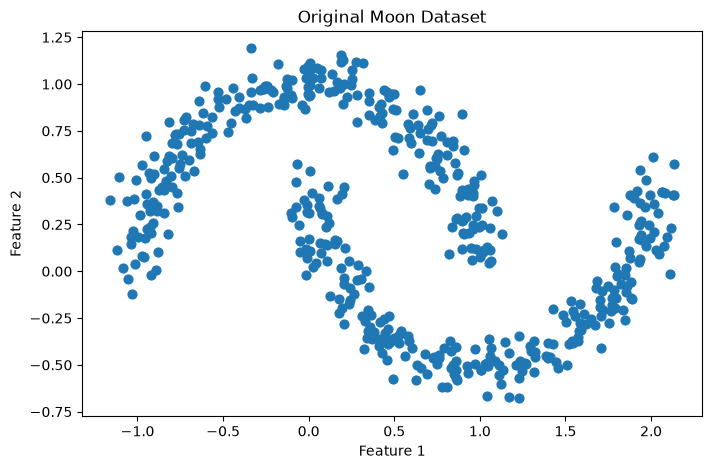

In [4]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],                              # First feature
    X[:, 1],                              # Second feature
    s=40                                  # Point size
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Original Moon Dataset")

plt.show()

# Scale the data 

In [5]:
scaler = StandardScaler()                 # Creates the standardization object

X_scaled = scaler.fit_transform(
    X                                     # Standardizes the features
)

# create spectral clustering 

In [7]:
spectral = SpectralClustering(
    n_clusters=2,                         # Number of clusters we want
    affinity="nearest_neighbors",         # Builds a graph using nearest-neighbor relationships
    n_neighbors=10,                       # Each point is connected to its 10 nearest neighbors
    assign_labels="kmeans",               # Uses K-Means on the spectral representation
    random_state=42                       # Makes the result reproducible
)

# Find and predict 

In [8]:
clusters = spectral.fit_predict(
    X_scaled                             # Build the graph and find the clusters
)

/Users/shyamalkar/Desktop/ML/mlvenv/lib/python3.14/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


# Evaluate with silhouette score

In [9]:
silhouette = silhouette_score(
    X_scaled,                             # Original feature data
    clusters                              # Spectral cluster assignments
)

print("Silhouette Score:", silhouette)

Silhouette Score: 0.38355256771289353


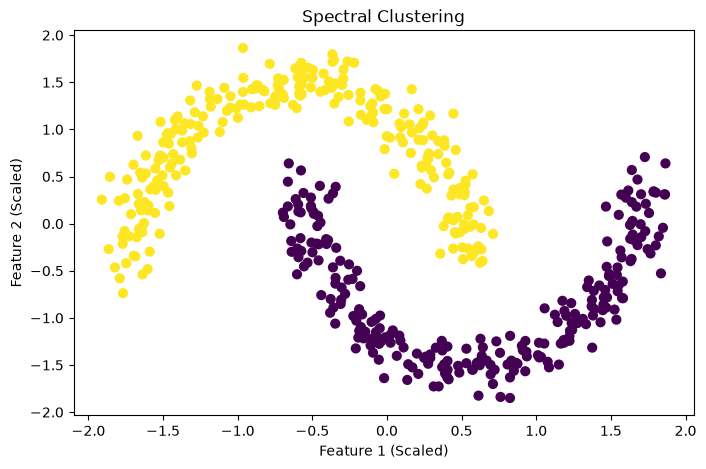

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],                       # First scaled feature
    X_scaled[:, 1],                       # Second scaled feature
    c=clusters,                           # Color according to cluster
    s=40                                  # Point size
)

plt.xlabel("Feature 1 (Scaled)")
plt.ylabel("Feature 2 (Scaled)")
plt.title("Spectral Clustering")

plt.show()

# One Important important answer. 

# The one of the important parameter affinity . 

`This is one of the most important spectral clustering concepts . `

`affinity determines . `

`How do we define simikarity between observations ?`

`Common option include :- nearest_neighbors.`
                            `rbf`

`nearest_neighbors - this creates graph based on nearby observations.`
`point A - Point B - point c `

`We used - affinity='nearest_neighbors `
`This is particularly useful for datasets where local neighborhood structure is important `

`n_neighbors, when using - affinity-"nearest_neighbors"`

`we have n_estimators = 10 that means, Each observation is connected to its 10 nearest neighbors when constructing the graph. `

# Hyperparameter experiment - n_neighbors 

In [11]:
neighbor_values = [5, 10, 15, 20, 30]

for n_neighbors in neighbor_values:

    model = SpectralClustering(
        n_clusters=2,                     # Keep the number of clusters fixed
        affinity="nearest_neighbors",     # Build graph from nearest neighbors
        n_neighbors=n_neighbors,          # Test different neighborhood sizes
        assign_labels="kmeans",            # Use K-Means for final label assignment
        random_state=42                   # Reproducibility
    )

    labels = model.fit_predict(
        X_scaled                          # Perform spectral clustering
    )

    score = silhouette_score(
        X_scaled,                         # Original dataset
        labels                            # Cluster assignments
    )

    print(
        f"n_neighbors={n_neighbors} | "
        f"silhouette={score:.3f}"
    )

n_neighbors=5 | silhouette=-0.148
n_neighbors=10 | silhouette=0.384
n_neighbors=15 | silhouette=0.384
n_neighbors=20 | silhouette=0.384
n_neighbors=30 | silhouette=0.387


/Users/shyamalkar/Desktop/ML/mlvenv/lib/python3.14/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/Users/shyamalkar/Desktop/ML/mlvenv/lib/python3.14/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/Users/shyamalkar/Desktop/ML/mlvenv/lib/python3.14/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/Users/shyamalkar/Desktop/ML/mlvenv/lib/python3.14/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


# Experiment - affinity 
`let's compare - nearest_neighbors, rbf . `

In [12]:
affinity_values = [
    "nearest_neighbors",
    "rbf"
]

for affinity in affinity_values:

    if affinity == "nearest_neighbors":

        model = SpectralClustering(
            n_clusters=2,                 # Number of clusters
            affinity=affinity,             # Use nearest-neighbor graph
            n_neighbors=10,               # Number of neighbors
            assign_labels="kmeans",        # Use K-Means for label assignment
            random_state=42               # Reproducibility
        )

    else:

        model = SpectralClustering(
            n_clusters=2,                 # Number of clusters
            affinity=affinity,             # Use RBF similarity
            gamma=1.0,                    # Controls how quickly similarity decreases with distance
            assign_labels="kmeans",        # Use K-Means for label assignment
            random_state=42               # Reproducibility
        )

    labels = model.fit_predict(
        X_scaled                          # Perform spectral clustering
    )

    score = silhouette_score(
        X_scaled,                         # Original dataset
        labels                            # Cluster assignments
    )

    print(
        f"{affinity}: {score:.3f}"
    )

nearest_neighbors: 0.384
rbf: 0.491


/Users/shyamalkar/Desktop/ML/mlvenv/lib/python3.14/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


# What is gamma ?
`When - affinity="rbf" . `
`we can use`
`gamma`
`it controls how quickly similarity decrease as points become farther apart . `

`High gamma`
`    ↓`
`similarity decreases quickly`
`   ↓`
`Very local relationships`

`Low gamma`
    `↓`
`Similarity decreases slowly`
    `↓`
`Broader relationships`

In [13]:
# experiment with gamma 

gamma_values = [0.1, 0.5, 1.0, 2.0, 5.0]

for gamma in gamma_values:

    model = SpectralClustering(
        n_clusters=2,                     # Keep number of clusters fixed
        affinity="rbf",                   # Use RBF similarity
        gamma=gamma,                      # Test different similarity scales
        assign_labels="kmeans",            # Use K-Means for final assignment
        random_state=42                   # Reproducibility
    )

    labels = model.fit_predict(
        X_scaled                          # Perform spectral clustering
    )

    score = silhouette_score(
        X_scaled,                         # Dataset
        labels                            # Cluster assignments
    )

    print(
        f"gamma={gamma} | "
        f"silhouette={score:.3f}"
    )

gamma=0.1 | silhouette=0.493
gamma=0.5 | silhouette=0.493
gamma=1.0 | silhouette=0.491
gamma=2.0 | silhouette=0.488
gamma=5.0 | silhouette=0.399
